## Items to do:
need to organize code more. Note:
1. where is skip heights
2. inputs from config file

Assess impacts of fit options (affect Chi2)
1. single scaling (fixed activity ratio)
2. variable bins vs fixed bins (chi2)
3. impact of first bin
4. lower stats (profile likelihood)?

attenuation goes opposite way... should add reflector at top of chamber

In [3]:
## Atown's stuff
import os
import sys
import time
sys.path.append("..")
from globalsC2 import *

import sys

import matplotlib.pyplot as plt
import numpy as np
import PickleLite as PL

# import MakeSpectra as MS
print(COMP2PATH)

CF4HOME: /Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4
COMP2PATH: /Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/comp2
Welcome to JupyROOT 6.27/01
/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/comp2


In [4]:
actCo = 4713000
actCs = 135500

actRatio = actCo / actCs
print("Activity Ratio Co-60 / Cs-137: ", actRatio)

fOmega = (1 - np.cos(2.0 * np.pi / 180))/2  # fraction of 4pi covered by detector at 2 degrees
print(fOmega * actCo)
print(fOmega * actCs)

thetaOpening = np.arctan(2/100)*180/np.pi
print("Detector opening angle (degrees): ", thetaOpening)

Activity Ratio Co-60 / Cs-137:  34.78228782287823
1435.5161295008365
41.27146945626212
Detector opening angle (degrees):  1.1457628381751035


In [5]:
# Example usage (uncomment and set COMP2PATH if not already in scope):
save_dir = os.path.join(COMP2PATH, "DataAnalysis", "saved_spectra2")

## opening multiple in one file
co_bare = PL.load_snap_list(os.path.join(save_dir, "rc_Co_bare_source.snap.pkl"))
print(type(co_bare[0]))
print(f"Loaded {len(co_bare)} Co bare LiteRun objects. First IDs:", [lr.id for lr in co_bare[:3]])

# Optional: tiny loader example which also works
# with open(os.path.join(save_dir, "rc_Co_bare_source.snap.pkl"), "rb") as f:
#   co_bare_loaded = pickle.load(f)
#   print(f"Loaded {len(co_bare_loaded)} Co bare snapshots. First IDs:", [d["id"] for d in co_bare_loaded[:3]])
#   print(type(co_bare_loaded[0]))

<class 'PickleLite.LiteRun'>
Loaded 5 Co bare LiteRun objects. First IDs: ['202203031411', '202203031118', '202203031135']


---
### Load data spectra

166300
110521
130428


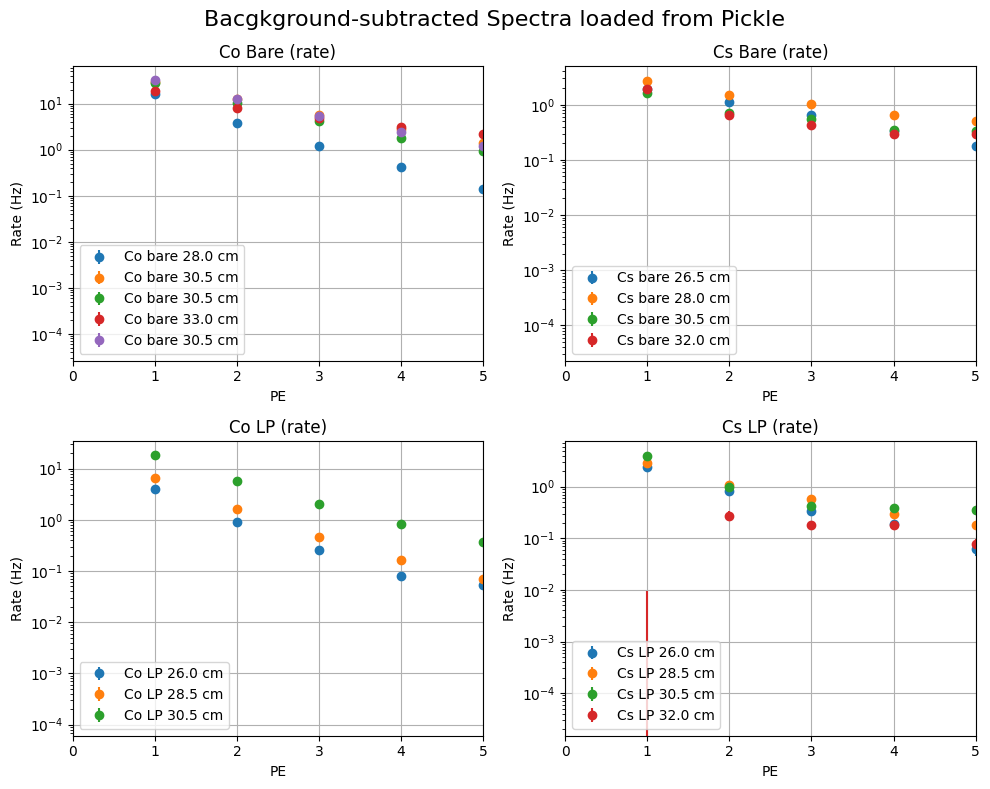

In [6]:
save_dir = os.path.join(COMP2PATH, "DataAnalysis", "saved_spectra2")

co_bare = PL.load_snap_list(os.path.join(save_dir, "rc_Co_bare_source.snap.pkl"))
cs_bare = PL.load_snap_list(os.path.join(save_dir, "rc_Cs_bare_source.snap.pkl"))
co_lp = PL.load_snap_list(os.path.join(save_dir, "rc_Co_LP_source.snap.pkl"))
cs_lp = PL.load_snap_list(os.path.join(save_dir, "rc_Cs_LP_source.snap.pkl"))

# Plot one example per category
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for lr in co_bare:
  lr.mpl_errorbar(axes[0,0], useCounts=False, label=f"Co bare {lr.height} cm", marker='o', linestyle='None')
axes[0,0].set_yscale('log'); axes[0,0].set_title("Co Bare (rate)"); axes[0,0].legend(); axes[0,0].grid(True)

for lr in cs_bare:
  lr.mpl_errorbar(axes[0,1], useCounts=False, label=f"Cs bare {lr.height} cm", marker='o', linestyle='None')
axes[0,1].set_yscale('log'); axes[0,1].set_title("Cs Bare (rate)"); axes[0,1].legend(); axes[0,1].grid(True)

for lr in co_lp:
  lr.mpl_errorbar(axes[1,0], useCounts=False, label=f"Co LP {lr.height} cm", marker='o', linestyle='None')
axes[1,0].set_yscale('log'); axes[1,0].set_title("Co LP (rate)"); axes[1,0].legend(); axes[1,0].grid(True)

for lr in cs_lp:
  lr.mpl_errorbar(axes[1,1], useCounts=False, label=f"Cs LP {lr.height} cm", marker='o', linestyle='None')
axes[1,1].set_yscale('log'); axes[1,1].set_title("Cs LP (rate)"); axes[1,1].legend(); axes[1,1].grid(True)

for rl in co_lp:
  print(np.sum(rl.counts_raw))

for ax in axes.flat:
  ax.set_xlabel("PE"); ax.set_ylabel("Rate (Hz)")
  ax.set_xlim(0, 5)

fig.suptitle("Bacgkground-subtracted Spectra loaded from Pickle", fontsize=16)
plt.tight_layout(); plt.show()

In [7]:
import json5 as json 
import CompHelpers.MCdataSet as MCH
import CompHelpers.Comparator_generic as COMP
import CompHelpers.RealDataSet as RD

with open("compConfig.json") as f:
  compConfig = json.load(f)

hSkipList = compConfig["comparison"]["hSkipList"]
print("hSkipList:", hSkipList)

with open(os.path.join(COMP2PATH, "pyScripts", "analysis.json")) as f:
  anaConfig = json.load(f)["analysis"]

hSkipList: [-1]


In [8]:
rds = RD.RealDataSet()

print(type(co_bare[0]))  # Should print the type of the first LiteRun object

rds.mCoLP = co_lp
rds.mCsLP = cs_lp
# rds.mCo = co_bare
# rds.mCs = cs_bare
# rds.mCoBare = co_bare
# rds.mCsBare = cs_bare

print(rds.mCoLP[0].mNEvents)

if rds.mCoLP[0].mHeight > 10:
  rds.ModifyHeights(hScale = compConfig["experiment"]["heightScale"])

rds.print()

<class 'PickleLite.LiteRun'>
167817

---- RealDataSet print() ----

    h         Nraw        Nsub     rate (Hz)    subRate (Hz)
Cs LP:
|    6.0 |  5.3e+04  |  5.25e+03  |   39.10 |   3.90
|    3.5 |  6.1e+04  |  7.73e+03  |   40.37 |   5.18
|    1.5 |  3.0e+04  |  5.39e+03  |   43.19 |   7.99
|    0.0 |  5.1e+04  |  2.99e+03  |   37.41 |   2.21

Co LP:
|    6.0 |  1.7e+05  |  2.21e+04  |   40.59 |   5.39
|    3.5 |  1.1e+05  |  2.24e+04  |   44.15 |   8.95
|    1.5 |  1.3e+05  |  5.79e+04  |   63.33 |  28.13


---
## load tools and MC spectra

In [9]:
pBatch3 = "/Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/batchOutput/gammaLP_Jan26_merged/"
# other = "gammaLP_Jan26_reduced"
mcDataPath = pBatch3
  
## making MC dataset
mc1 = MCH.MCdataSet(mcDataPath+"3/", buildOptions='all', skipRootHeights=[0.0])

# mc1.doCAcorrection_BinomialMC(compConfig["mc_analysis"]["NCA"]) # makes var mNPE_corr
mc1.setup_forComparison(anaConfig["nBins"], anaConfig["binLow"], anaConfig["binHigh"], variable='mNPE')
print("nbeam is:", mc1.mAllRuns[0].Nbeam)


print("--------\nlight yield is:", mc1.mAllRuns[0].mPhysPars.ly, " ph/keV")


FileNotFoundError: [Errno 2] No such file or directory: '/Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/batchOutput/gammaLP_Jan26_merged/3/'

In [ ]:
fig, (ax1, ax2) = plt.subplots(figsize=(8,6), nrows=2, sharex=True)
ax = ax1
for mc, dat in zip(mc1.mCoLPList, rds.mCoLP[::-1]):
  
  line = dat.mpl_errorbar(ax1, label=f"Data {32-dat.height} cm", marker="x", linestyle="None")
  
  dataArea = np.sum(dat.BkgCorrected_rawCounts)
  
  mcArea = np.sum(mc.mRaw_Counts)
  
  scale = 2*dataArea/mcArea
  
  # mc.mpl_errorbar(ax1, scale=scale, hshift = 0.1, label=f"MC {mc.mRunPars.gammaHeight} cm", marker="X", linestyle="None")
  mc.mpl_hist(ax1, scale = scale, hshift = 0, label=f"MC {mc.mRunPars.gammaHeight} cm", histtype='step', color = line.get_color())
  print(type(mc))

for mc, dat in zip(mc1.mCsLpList, rds.mCsLP[::-1]):
  # print(dat.height)
  # if 32-dat.height < 1:
  #   continue
  line = dat.mpl_errorbar(ax2, label=f"Data {32-dat.height} cm", marker="o", linestyle="None")
  
  dataArea = np.sum(dat.BkgCorrected_rawCounts)
  
  mcArea = np.sum(mc.mRaw_Counts)
  
  scale = dataArea/mcArea
  
  # mc.mpl_errorbar(ax2, scale=scale, hshift = 0.1, label=f"MC {mc.mRunPars.gammaHeight} cm", marker="x", linestyle="None")
  mc.mpl_hist(ax2, scale = scale, hshift = 0, label=f"MC {mc.mRunPars.gammaHeight} cm", histtype='step', color = line.get_color())

ax1.set_xlim(0, 20)
# ax1.vlines(range(1,11), ymin=1e-3, ymax=1e5, colors='gray', linestyles='dashed', alpha=0.5)
  
  
ax1.set_yscale('log')
ax.set_xlabel("PE")
ax.set_ylabel("Counts")
ax.set_title("MC Co LP Spectra")

ax2.set_yscale('log')
ax2.set_xlabel("PE")
ax2.set_ylabel("Counts")
ax2.set_title("MC Cs LP Spectra")

ax1.legend()
ax2.legend(loc='upper right')

plt.show()

NameError: name 'plt' is not defined

---
### RC MC comparisons

To properly do comparison, must use the number of counts in the real data. so data corrected counts = raw counts - bkg rate x run time

In [ ]:
comp1 = COMP.Comparator(rds)
comp1.hScale = compConfig["experiment"]["heightScale"]
comp1.mMCDataSet = mc1

# mc1.print()
# print("\n ---------------- \n")
# # rds.print(verbose=1, hScale = 0)
# print("\n ---------------- \n")
# comp1.SetBinRanges(1, 5, mode="value")
# res = mc1.findRunByHeight(3.5, key="colp")  # Test findRunByHeight
# print(mc1.gammaMap.keys())
# print(res)

comp1.auto_map_by_common_heights(keys = ["colp", "cslp"], heightSkipList=[0.0], verbose = 0)
# comp1.print(mcVerb = 1, dataVerb = 1)

# comp1.SetBinRanges(firstBin=2, lastBin = 8, mode="value", verbose=0);
comp1.SetBinRanges_byCountLimit(firstBin=1, countLimit=5, option="both", verbose=1)
print("analyzing keys:", comp1.keysUsed)

comp1.GuessOverallScaling()
gsc_co = comp1.statsCoLP.nuisGuess
gsc_cs = comp1.statsCsLP.nuisGuess

print(comp1.coLPpairs[0].GetPrefac())
print(comp1.coLPpairs[0].mc.mRunPars.gammaAngle)

analyzing keys: ['colp', 'cslp']
0.0004097299523736
1.5


LiteRun 202204111600: plotting background-corrected counts
Cs h=6.0: bins [1-6] -> x=[2.0-7.0]
LiteRun 202204111454: plotting background-corrected counts
Cs h=3.5: bins [1-5] -> x=[2.0-6.0]
LiteRun 202204111423: plotting background-corrected counts
Cs h=1.5: bins [1-19] -> x=[2.0-20.0]
LiteRun 202204131513: plotting background-corrected counts
Co h=6.0: bins [1-7] -> x=[2.0-8.0]
LiteRun 202204131317: plotting background-corrected counts
Co h=3.5: bins [1-7] -> x=[2.0-8.0]
LiteRun 202204131122: plotting background-corrected counts
Co h=1.5: bins [1-14] -> x=[2.0-15.0]


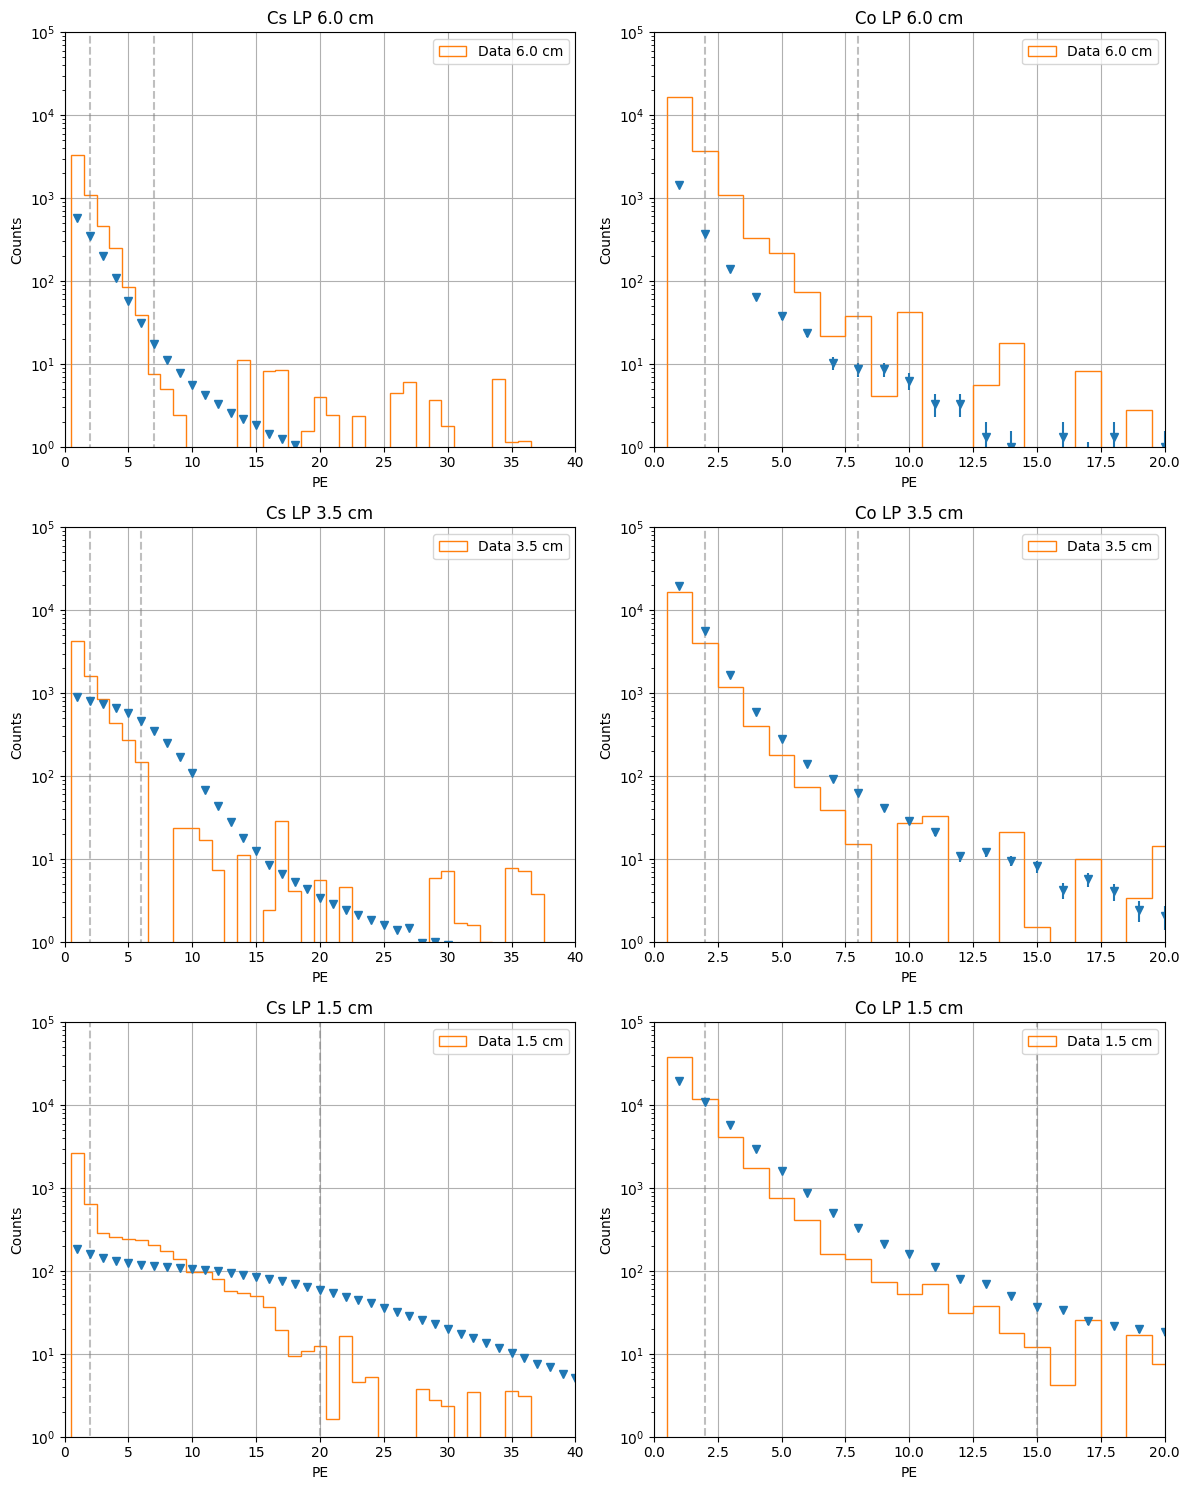

In [ ]:
## can we plot the overlayed histograms at the best scaling?

fig, axes = plt.subplots(3, 2, figsize=(12, 15))
axA = axes[:, 0]  # First column (Co)
axB = axes[:, 1]  # Second column (Cs)

## cs plots
for i, pair in enumerate(comp1.csLPpairs):
  ax = axA[i]
  # completeMCscale = csScale * pair.GetPrefac()
  # pair.mc.mpl_errorbar(ax, scale=completeMCscale, hshift = 0.0, label=f"MC {pair.mc.mRunPars.gammaHeight} cm", marker="X", linestyle="None")
  # singleScaleCs = singleScale * pair.GetPrefac() * 1
  
  # csScale = comp1._statsMap.get('cslp').nuisScaling * pair.GetPrefac()
  # print("this is cs nuis scaling:", comp1._statsMap.get('cslp').nuisScaling)
  csScale = pair.FixedScaling(rgamma = actCs)
  pair.mc.mpl_errorbar(ax, scale=csScale, hshift = 0.0, marker="v", linestyle="None")
  
  # pair.rc.mpl_errorbar(ax, label=f"Data {pair.rc.height} cm", marker="o", linestyle="None")
  pair.rc.mpl_hist(ax, verbose = 1, label=f"Data {comp1.hScale-pair.rc.height} cm", histtype='step')
  
  ## vertical lines from StatsManager bin positions (specific to each pair)
  fx_fromBin = pair.rc.mBinX[pair.stats.firstBin]
  lx_fromBin = pair.rc.mBinX[pair.stats.lastBin]
  print(f"Cs h={pair.height:.1f}: bins [{pair.stats.firstBin}-{pair.stats.lastBin}] -> x=[{fx_fromBin:.1f}-{lx_fromBin:.1f}]")
  ax.vlines([fx_fromBin, lx_fromBin], ymin=1e-3, ymax=1e5, colors='gray', linestyles='dashed', alpha=0.5)
  
  ax.set_title(f"Cs LP {comp1.hScale-pair.rc.height} cm")
  ax.set_xlabel("PE")
  ax.set_ylabel("Counts")
  ax.legend()
  ax.set_yscale('log')
  
for i, pair in enumerate(comp1.coLPpairs):
  ax = axB[i]
  # completeMCscale = coScale * pair.GetPrefac()
  # pair.mc.mpl_errorbar(ax, scale=completeMCscale, hshift = 0.0, label=f"MC {pair.mc.mRunPars.gammaHeight} cm", marker="x", linestyle="None")
  
  # singleScaleCo = singleScale * pair.GetPrefac() * actCo/actCs
  coScale = pair.FixedScaling(rgamma = actCo)
  pair.mc.mpl_errorbar(ax, scale=coScale, hshift = 0.0, marker="v", linestyle="None")
  
  # pair.rc.mpl_errorbar(ax, label=f"Data {pair.rc.height} cm", marker="o", linestyle="None")
  pair.rc.mpl_hist(ax, verbose = 1, label=f"Data {comp1.hScale-pair.rc.height} cm", histtype='step')
  
  ## vertical lines from StatsManager bin positions (specific to each pair)
  fx_fromBin = pair.rc.mBinX[pair.stats.firstBin]
  lx_fromBin = pair.rc.mBinX[pair.stats.lastBin]
  print(f"Co h={pair.height:.1f}: bins [{pair.stats.firstBin}-{pair.stats.lastBin}] -> x=[{fx_fromBin:.1f}-{lx_fromBin:.1f}]")
  ax.vlines([fx_fromBin, lx_fromBin], ymin=1e-3, ymax=1e5, colors='gray', linestyles='dashed', alpha=0.5)
  
  ax.set_title(f"Co LP {comp1.hScale-pair.rc.height} cm")
  ax.set_xlabel("PE")
  ax.set_ylabel("Counts")
  ax.legend()
  ax.set_yscale('log')

axs = np.append(axA, axB)
[ax.set_xlim(0, 40) for ax in axA];
[ax.set_xlim(0, 20) for ax in axB];

[ax.set_ylim(1, 1e5) for ax in axs];

[ax.grid() for ax in axs];
plt.tight_layout()
plt.show()

---
### Full dataset analysis

In [ ]:
print(os.listdir(mcDataPath))

['0', '7', '6', '1', '4', '3', '2', '5']


In [ ]:
## making MC dataset - collect results silently, print summary at end
chis = []
lyList = []
nbeamList = []
binInfoList = []  # Store bin range info including warnings
totalChis = []

comp = COMP.Comparator(rds)
sortedListDir = sorted(os.listdir(mcDataPath))

# Suppress prints during loop - collect everything
import io
import contextlib

for folder in sortedListDir:
  
  if int(folder) == 8: ## only Co simulated in here
    continue
  
  # Capture any stray output from MCdataSet loading
  with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    mc = MCH.MCdataSet(mcDataPath+folder+"/", buildOptions='all', skipRootHeights=hSkipList, verbose=0)
    
    ly = mc.mAllRuns[0].mPhysPars.ly
    nbeam = mc.mAllRuns[0].Nbeam
    if ly < 1: # garbage
      continue
    
    ## add CA correction here
    mc.doCAcorrection_BinomialMC(compConfig["mc_analysis"]["NCA"]) # makes var mNPE_corr
    mc.setup_forComparison(anaConfig["nBins"], anaConfig["binLow"], anaConfig["binHigh"], variable='mNPE_corr')
    mc.check_physPars_andDetPars(verbose=0)
  
  comp.hScale = compConfig["experiment"]["heightScale"]
  comp.mMCDataSet = mc
  comp.auto_map_by_common_heights(keys=["colp", "cslp"], heightSkipList=hSkipList, verbose=0)
  
  ## by low lim on byCountLimit goes by bins, so 1 excludes 1PE (first) bin
  ## SetBinRanges, mode = value goes by x value, so firstBin = 1 includes 1PE (0th bin) and above
  if compConfig["comparison"]["compFlag"] == "fixed":
    binInfo = comp.SetBinRanges(firstBin=compConfig["comparison"]["compPE_low"], lastBin=compConfig["comparison"]["compPE_high"], mode="value", verbose=0)
  elif compConfig["comparison"]["compFlag"] == "countLimit":
    binInfo = comp.SetBinRanges_byCountLimit(firstBin=compConfig["comparison"]["compBin_low"], countLimit=compConfig["comparison"]["compCounts_high"], option="both", verbose=0)
  else:
    raise ValueError(f"Invalid compFlag: {compConfig['comparison']['compFlag']}")
  
  chi2_co = comp.FixedScaling_Keychi2(key="colp", rgamma = actCo)
  chi2_cs = comp.FixedScaling_Keychi2(key="cslp", rgamma = actCs)
  
  functionTotalChi2 = comp.GetFixedScaling_chi2(keys = ["colp", "cslp"], rgammas=[actCo, actCs])
  
  chis.append([chi2_co, chi2_cs])
  lyList.append(ly)
  nbeamList.append(nbeam)
  binInfoList.append(binInfo)
  
  totalChi2 = chi2_co + chi2_cs
  totalNbins = comp.GetTotalNBins(keys=["colp", "cslp"])
  reducedChi2 = totalChi2 / (totalNbins - 0)  # no fit params for fixed scaling
  totalChis.append([totalChi2, totalNbins, reducedChi2])

# Sort by LY
sorted_indices = np.argsort(lyList)
lyList = np.array(lyList)[sorted_indices]
chis = np.array(chis)[sorted_indices]
nbeamList = np.array(nbeamList)[sorted_indices]
binInfoList = [binInfoList[i] for i in sorted_indices]

totalChis = np.array(totalChis)[sorted_indices]
totalChiOnly = totalChis[:,0]
nBinsOnly = totalChis[:,1]
redChiOnly = totalChis[:,2]

### Printing ###
print(f"{'Folder':<7} {'LY':<5} {'Chi2(Co)':<10} {'Chi2(Cs)':<10} {'RedChi2':<10} {'nBins':<6}")
print("="*55)
for i, folder in enumerate(np.array(sortedListDir)[sorted_indices]):
  print(f"{folder:<7} {lyList[i]:<5.1f} {chis[i,0]:<10.1f} {chis[i,1]:<10.1f} {redChiOnly[i]:<10.2f} {nBinsOnly[i]:<6.0f}")
print("-"*55)
print(f"Total folders: {len(lyList)}")

# Low-stat warnings summary
warnings = [(f, lyList[i], info) for i, f in enumerate(np.array(sortedListDir)[sorted_indices]) 
            for info in binInfoList[i] if info.get('status') == -1]
if warnings:
  print(f"\n⚠️ {len(warnings)} pairs with low MC stats (bins < countLimit in range)")

Folder  LY    Chi2(Co)   Chi2(Cs)   RedChi2    nBins 
6       1.0   68864.8    20256.3    2475.59    36    
0       2.0   10494.9    998.7      302.46     38    
1       3.0   1501.4     101.2      42.18      38    
2       4.0   185.2      404.9      15.53      38    
3       5.0   1365.3     789.1      56.69      38    
4       6.0   3618.5     1122.8     124.77     38    
5       7.0   6261.0     1418.3     202.09     38    
-------------------------------------------------------
Total folders: 7


--------

skipping heights [0.0, 6.0]
comparing via method: countLimit
count limit: 2 10
min ly: 4.0 min chi2: 590.1595906378822
Fit converged  |  x0 = 3.892 ± 0.000  |  y0 = 590.160 ± 0.033  |  a  = 1273.6238 ± 0.7194  |  npts = 3
-------
fit success True
fit minimum at LY = 3.89 +/- 0.00
minimum chi2 = 590.16 +/- 0.03
width error on chi2 0.028020727832527046


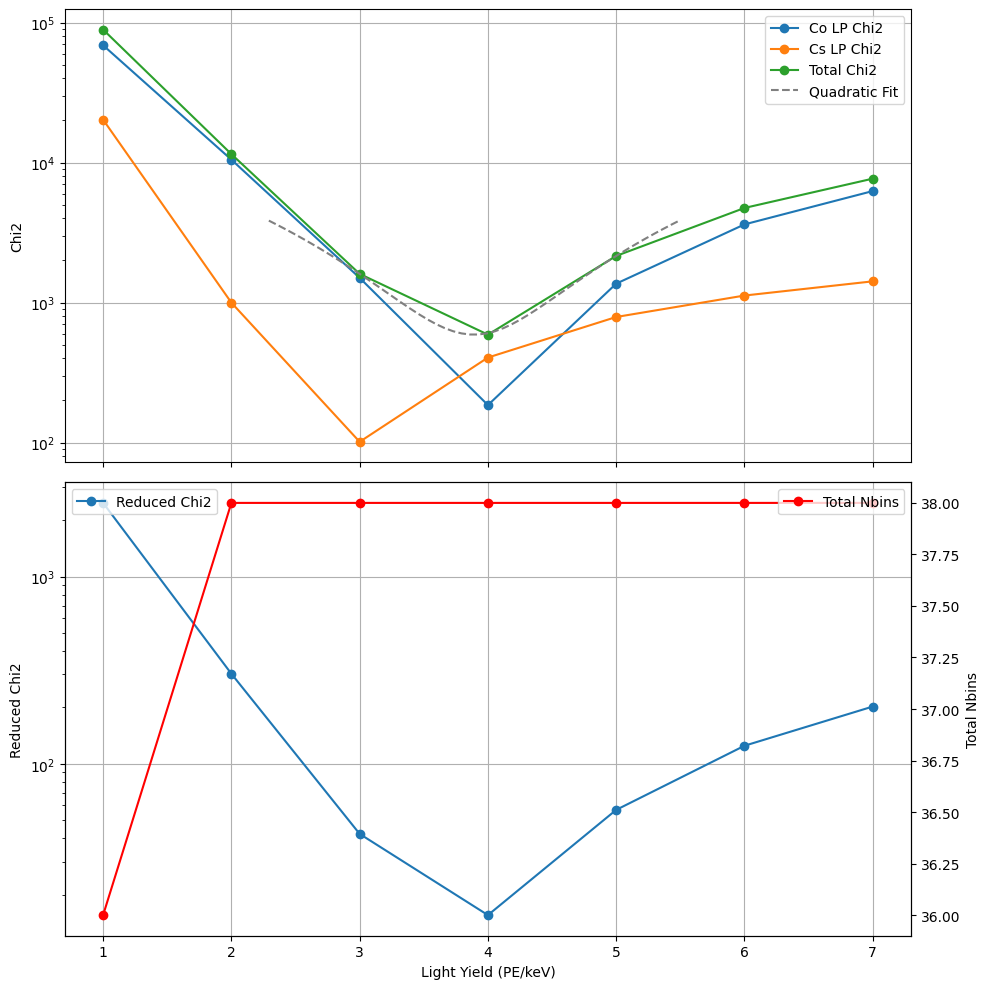

In [ ]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 10), sharex=True)

import CompHelpers.Fitters as FTS

ax1.plot(lyList, chis[:,0], marker='o', label='Co LP Chi2')
ax1.plot(lyList, chis[:,1], marker='o', label='Cs LP Chi2')
ax1.plot(lyList, totalChiOnly, marker='o', label='Total Chi2')
ax1.set_ylabel("Chi2")
ax1.legend()
ax1.grid(True)
ax1.set_yscale('log')


ax2.plot(lyList, redChiOnly, marker='o', label='Reduced Chi2')
axx = ax2.twinx()
axx.plot(lyList, nBinsOnly, marker='o', color="red", label='Total Nbins')
ax2.set_ylabel("Reduced Chi2")
ax2.set_xlabel("Light Yield (PE/keV)")
ax2.set_yscale('log')
ax2.legend(loc='upper left')
axx.set_ylabel("Total Nbins")
axx.legend(loc='upper right')
ax2.grid(True)

print("--------\n\nskipping heights", hSkipList)
print("comparing via method:", compConfig["comparison"]["compFlag"])

if compConfig["comparison"]["compFlag"] == "countLimit":
  print("count limit:", compConfig["comparison"]["compBin_low"], compConfig["comparison"]["compCounts_high"])
elif compConfig["comparison"]["compFlag"] == "fixed":
  print("PE range:", compConfig["comparison"]["compPE_low"], "-", compConfig["comparison"]["compPE_high"])

#### Fitting ####
xfitsub = 1.6
xfitplus = 1.6
minLYvalue = lyList[np.argmin(totalChiOnly)]
print("min ly:", minLYvalue, "min chi2:", min(totalChiOnly))

chiToPass = totalChiOnly
if minLYvalue <= 2:
  chiToPass = redChiOnly
res = FTS.fit_quadratic_minimum(lyList, chiToPass)
print("-------\nfit success",res['success'])
print(f"fit minimum at LY = {res['x0']:.2f} +/- {res['x0_err']:.2f}")
print(f"minimum chi2 = {res['y0']:.2f} +/- {res['y0_err']:.2f}")

print("width error on chi2", 1/np.sqrt(res['a']))  # rough estimate of LY uncertainty from fit curvature

## plot the fit
minXfromFit = res['x0']
x_fit = np.linspace(minXfromFit-xfitsub, minXfromFit+xfitplus, 50)
y_fit = FTS.quadratic(x_fit, res['a'], res['x0'], res['y0'])

if minLYvalue > 2:
  ax1.plot(x_fit, y_fit, label='Quadratic Fit', color='gray', linestyle='dashed')
  ax1.legend()
else:
  ax2.plot(x_fit, y_fit, label='Quadratic Fit', color='gray', linestyle='dashed')
  ax2.legend(loc='upper left')

plt.tight_layout()


In [ ]:
## Systematic scan: firstBin x heightSkip combinations
## Uses SetBinRanges_byCountLimit for all cases (fixed scaling)

import CompHelpers.Fitters as FTS

firstBin_list = [0, 1, 2]  # 0-based bin indices: 1 -> 2PE, 2 -> 3PE
hSkip_configs = {
    "all":       [0.0],
    "skip 6cm":  [0.0, 6.0],
    "skip 1.5cm":[0.0, 1.5],
}
countLim = compConfig["comparison"]["compCounts_high"]

scan_results = {}

for fb in firstBin_list:
  for hLabel, hSkip in hSkip_configs.items():
    tag = f"firstBin={fb}, {hLabel}"
    
    lyArr = []
    totalChi2Arr = []
    totalNbinsArr = []
    
    compS = COMP.Comparator(rds)
    
    for folder in sorted(os.listdir(mcDataPath)):
      if int(folder) == 8:
        continue
      
      with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        mcS = MCH.MCdataSet(mcDataPath+folder+"/", buildOptions='all', skipRootHeights=hSkip, verbose=0)
        ly = mcS.mAllRuns[0].mPhysPars.ly
        if ly < 1:
          continue
        mcS.doCAcorrection_BinomialMC(compConfig["mc_analysis"]["NCA"])
        mcS.setup_forComparison(anaConfig["nBins"], anaConfig["binLow"], anaConfig["binHigh"], variable='mNPE_corr')
        mcS.check_physPars_andDetPars(verbose=0)
      
      compS.hScale = compConfig["experiment"]["heightScale"]
      compS.mMCDataSet = mcS
      compS.auto_map_by_common_heights(keys=["colp", "cslp"], heightSkipList=hSkip, verbose=0)
      compS.SetBinRanges_byCountLimit(firstBin=fb, countLimit=countLim, option="both", verbose=-1)
      
      chi2_co = compS.FixedScaling_Keychi2(key="colp", rgamma=actCo)
      chi2_cs = compS.FixedScaling_Keychi2(key="cslp", rgamma=actCs)
      
      lyArr.append(ly)
      totalChi2Arr.append(chi2_co + chi2_cs)
      totalNbinsArr.append(compS.GetTotalNBins(keys=["colp", "cslp"]))
    
    # Sort by LY
    idx = np.argsort(lyArr)
    lyArr = np.array(lyArr)[idx]
    totalChi2Arr = np.array(totalChi2Arr)[idx]
    totalNbinsArr = np.array(totalNbinsArr)[idx]
    reducedChi2Arr = totalChi2Arr / (totalNbinsArr - 0)  # no fit params for fixed scaling
    
    # Fit quadratic
    print("--\nfitting case:", tag)
    
    ## check total chi2 min
    minLYvalue = lyArr[np.argmin(totalChi2Arr)]
    minLY_reduced = lyArr[np.argmin(reducedChi2Arr)]
    
    res = None
    resReduced = None
    if minLYvalue != 1 and minLYvalue != 7:
      res = FTS.fit_quadratic_minimum(lyArr, totalChi2Arr)
    if minLY_reduced != 1 and minLY_reduced != 7:
      resReduced = FTS.fit_quadratic_minimum(lyArr, reducedChi2Arr)
    
    scan_results[tag] = {
        'ly': lyArr,
        'totalChi2': totalChi2Arr,
        'reducedChi2': reducedChi2Arr,
        'totalNbins': totalNbinsArr,
        'fit': res,
        'fitReduced': resReduced,
    }


--
fitting case: firstBin=0, all
Fit converged  |  x0 = 6.490 ± 0.000  |  y0 = 343081.389 ± 0.000  |  a  = 14219.2427 ± 0.8815  |  npts = 3
Fit converged  |  x0 = 6.490 ± 0.002  |  y0 = 5718.023 ± 0.007  |  a  = 236.9879 ± 0.8816  |  npts = 3
--
fitting case: firstBin=0, skip 6cm
Fit converged  |  x0 = 3.861 ± 0.000  |  y0 = 72017.767 ± 0.006  |  a  = 4406.1020 ± 0.7273  |  npts = 3
Fit converged  |  x0 = 3.861 ± 0.004  |  y0 = 1565.604 ± 0.266  |  a  = 95.7854 ± 0.7273  |  npts = 3
--
fitting case: firstBin=0, skip 6cm
Fit converged  |  x0 = 3.861 ± 0.000  |  y0 = 72017.767 ± 0.006  |  a  = 4406.1020 ± 0.7273  |  npts = 3
Fit converged  |  x0 = 3.861 ± 0.004  |  y0 = 1565.604 ± 0.266  |  a  = 95.7854 ± 0.7273  |  npts = 3
--
fitting case: firstBin=0, skip 1.5cm
--
fitting case: firstBin=0, skip 1.5cm
--
fitting case: firstBin=1, all
Fit converged  |  x0 = 6.546 ± 0.000  |  y0 = 39749.419 ± 0.001  |  a  = 1872.9132 ± 0.8830  |  npts = 3
Fit converged  |  x0 = 6.546 ± 0.017  |  y0 = 736

In [ ]:
print("\n\n=== Systematic Scan Summary (Fixed Scaling) ===")

# Total chi2 fits
print(f"\n--- Total χ² fits ---")
print(f"{'Case':<30} {'LY_min':>8} {'± LY':>8} {'χ²_min':>8} {'nBins*':>7} {'redχ²':>7} {'fit ok':>6}")
print("=" * 82)
for tag, r in scan_results.items():
    fit = r['fit']
    if fit is not None:
      nBins_at_min = r['totalNbins'][np.argmin(np.abs(r['ly'] - fit['x0']))]
      redChi2_at_min = fit['y0'] / (nBins_at_min - 0)  # no fit params for fixed scaling
      print(f"{tag:<30} {fit['x0']:>8.2f} {fit['x0_err']:>8.2f} {fit['y0']:>8.1f} {nBins_at_min:>7.0f} {redChi2_at_min:>7.2f} {'✓' if fit['success'] else '✗':>6}")
    else:
      print(f"{tag:<30} {'(min at edge, skipped)':>52}")

# Reduced chi2 fits
print(f"\n--- Reduced χ² fits ---")
print(f"{'Case':<30} {'LY_min':>8} {'± LY':>8} {'redχ²_min':>9} {'nBins*':>7} {'fit ok':>6}")
print("=" * 76)
for tag, r in scan_results.items():
    fit = r['fitReduced']
    if fit is not None:
      nBins_at_min = r['totalNbins'][np.argmin(np.abs(r['ly'] - fit['x0']))]
      print(f"{tag:<30} {fit['x0']:>8.2f} {fit['x0_err']:>8.2f} {fit['y0']:>9.3f} {nBins_at_min:>7.0f} {'✓' if fit['success'] else '✗':>6}")
    else:
      print(f"{tag:<30} {'(min at edge, skipped)':>46}")

print(f"\n* nBins at the LY closest to the fitted minimum")
print(f"  countLimit = {countLim}, fit range = -{xfitsub}/+{xfitplus} around raw min")
print(f"  redχ² denominator = nBins - 0 (no fit params for fixed scaling)")



=== Systematic Scan Summary (Fixed Scaling) ===

--- Total χ² fits ---
Case                             LY_min     ± LY   χ²_min  nBins*   redχ² fit ok
firstBin=0, all                    6.49     0.00 343081.4      60 5718.02      ✓
firstBin=0, skip 6cm               3.86     0.00  72017.8      46 1565.60      ✓
firstBin=0, skip 1.5cm                                       (min at edge, skipped)
firstBin=1, all                    6.55     0.00  39749.4      54  736.10      ✓
firstBin=1, skip 6cm               4.13     0.00   3457.1      42   82.31      ✓
firstBin=1, skip 1.5cm                                       (min at edge, skipped)
firstBin=2, all                    5.55     0.00  12447.4      48  259.32      ✓
firstBin=2, skip 6cm               3.89     0.00    590.2      38   15.53      ✓
firstBin=2, skip 1.5cm                                       (min at edge, skipped)

--- Reduced χ² fits ---
Case                             LY_min     ± LY redχ²_min  nBins* fit ok
firstBin=

In [ ]:
print("hi")

hi
